# EXPT NO: 6 — IMPLEMENTATION OF LONG SHORT-TERM MEMORY (LSTM) FOR SENTIMENT ANALYSIS

**NAME:** NIVASRI T  
**ROLL NO:** 24BAD081  
**DATE:** 12.10.2026

In [1]:
STUDENT_NAME = "NIVASRI T"
ROLL_NO = "24BAD081"

import re, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report,
                             ConfusionMatrixDisplay)

SEED = 42
np.random.seed(SEED); random.seed(SEED); tf.random.set_seed(SEED)
print(f"Name: {STUDENT_NAME} | Roll No: {ROLL_NO}")
print("TensorFlow version:", tf.__version__)

Name: NIVASRI T | Roll No: 24BAD081
TensorFlow version: 2.21.0


## PART A: DATASET PREPARATION

[NIVASRI T | 24BAD081] PART A: Dataset Preparation

17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Training reviews : 25000
Testing reviews  : 25000
1641221/1641221 ━━━━━━━━━━━━━━━━━━━━ 1s 1us/step

Sample 1 | Label: 1 (Positive)
<START> this film was just brilliant casting location scenery story direction everyone's really suited the part they played and you could just imagine being there robert <OOV> is an amazing actor and now the same being director <OOV> father came from the same scottish island as myself so i loved the ...

Sample 2 | Label: 0 (Negative)
<START> big hair big boobs bad music and a giant safety pin these are the words to best describe this terrible movie i love cheesy horror movies and i've seen hundreds but this had got to be on of the worst ever made the plot is paper thin and ridiculous the acting is an abomination the script is co ...

Sample 3 | Label: 0 (Negative)
<START> this has to be one of the worst films of the 1990s when my friends i were watching t

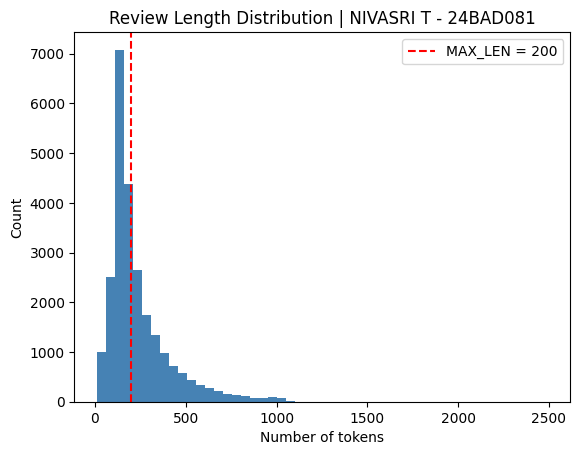

In [2]:
print(f"[{STUDENT_NAME} | {ROLL_NO}] PART A: Dataset Preparation\n")

# 1. Load the IMDB Movie Reviews dataset (top 10,000 most frequent words)
VOCAB_SIZE = 10000
MAX_LEN = 200

(x_train_full, y_train_full), (x_test, y_test) = imdb.load_data(num_words=VOCAB_SIZE)
print("Training reviews :", len(x_train_full))
print("Testing reviews  :", len(x_test))

# 2. Build the vocabulary: word -> integer index (Keras reserves 0=PAD, 1=START, 2=OOV, 3=UNUSED)
word_index = imdb.get_word_index()
word_index = {w: (i + 3) for w, i in word_index.items()}
word_index["<PAD>"], word_index["<START>"], word_index["<OOV>"], word_index["<UNUSED>"] = 0, 1, 2, 3
reverse_word_index = {i: w for w, i in word_index.items()}

def decode_review(seq):
    return " ".join(reverse_word_index.get(i, "?") for i in seq)

# 3. Explore sample reviews and their labels
label_names = {0: "Negative", 1: "Positive"}
for i in range(3):
    print(f"\nSample {i+1} | Label: {y_train_full[i]} ({label_names[y_train_full[i]]})")
    print(decode_review(x_train_full[i])[:300], "...")

# 4. Class distribution
print("\nClass distribution (train):")
print(pd.Series(y_train_full).map(label_names).value_counts())

# 5. Review length statistics
lengths = [len(s) for s in x_train_full]
print(f"\nReview length -> mean: {np.mean(lengths):.1f}, median: {np.median(lengths):.0f}, max: {max(lengths)}")
plt.hist(lengths, bins=50, color="steelblue")
plt.axvline(MAX_LEN, color="red", linestyle="--", label=f"MAX_LEN = {MAX_LEN}")
plt.title(f"Review Length Distribution | {STUDENT_NAME} - {ROLL_NO}")
plt.xlabel("Number of tokens"); plt.ylabel("Count"); plt.legend(); plt.show()

In [3]:
# 6. Text preprocessing helper (lowercase, remove symbols, tokenize) - reused later in Part D
def preprocess_text(text):
    text = text.lower()                          # lowercase
    text = re.sub(r"<br\s*/?>", " ", text)        # remove HTML tags
    text = re.sub(r"[^a-z0-9\s']", " ", text)     # remove special characters
    tokens = text.split()                        # tokenize into words
    return tokens

def text_to_sequence(text):
    tokens = preprocess_text(text)
    seq = [word_index["<START>"]]
    for t in tokens:
        idx = word_index.get(t, word_index["<OOV>"])
        seq.append(idx if idx < VOCAB_SIZE else word_index["<OOV>"])
    return seq

demo = "This movie was GREAT!!! <br /> Loved it :)"
print("Raw text  :", demo)
print("Tokens    :", preprocess_text(demo))
print("Sequence  :", text_to_sequence(demo))

# 7. Pad sequences to equal length
x_train_full = pad_sequences(x_train_full, maxlen=MAX_LEN, padding="pre", truncating="post")
x_test = pad_sequences(x_test, maxlen=MAX_LEN, padding="pre", truncating="post")

# 8. Split into training and validation sets (80/20)
x_train, x_val, y_train, y_val = train_test_split(
    x_train_full, y_train_full, test_size=0.2, random_state=SEED, stratify=y_train_full)

print("\nShapes after padding & splitting:")
print("x_train:", x_train.shape, "| x_val:", x_val.shape, "| x_test:", x_test.shape)
print(f"[{STUDENT_NAME} | {ROLL_NO}] Part A completed.")

Raw text  : This movie was GREAT!!! <br /> Loved it :)
Tokens    : ['this', 'movie', 'was', 'great', 'loved', 'it']
Sequence  : [1, 14, 20, 16, 87, 447, 12]

Shapes after padding & splitting:
x_train: (20000, 200) | x_val: (5000, 200) | x_test: (25000, 200)
[NIVASRI T | 24BAD081] Part A completed.


## PART B: IMPLEMENTING THE LSTM MODEL

[NIVASRI T | 24BAD081] PART B: Building the LSTM Model



/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "LSTM_Sentiment_24BAD081"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 200, 64)        │       640,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 673,089 (2.57 MB)

 Trainable params: 673,089 (2.57 MB)

 Non-trainable params: 0 (0.00 B)

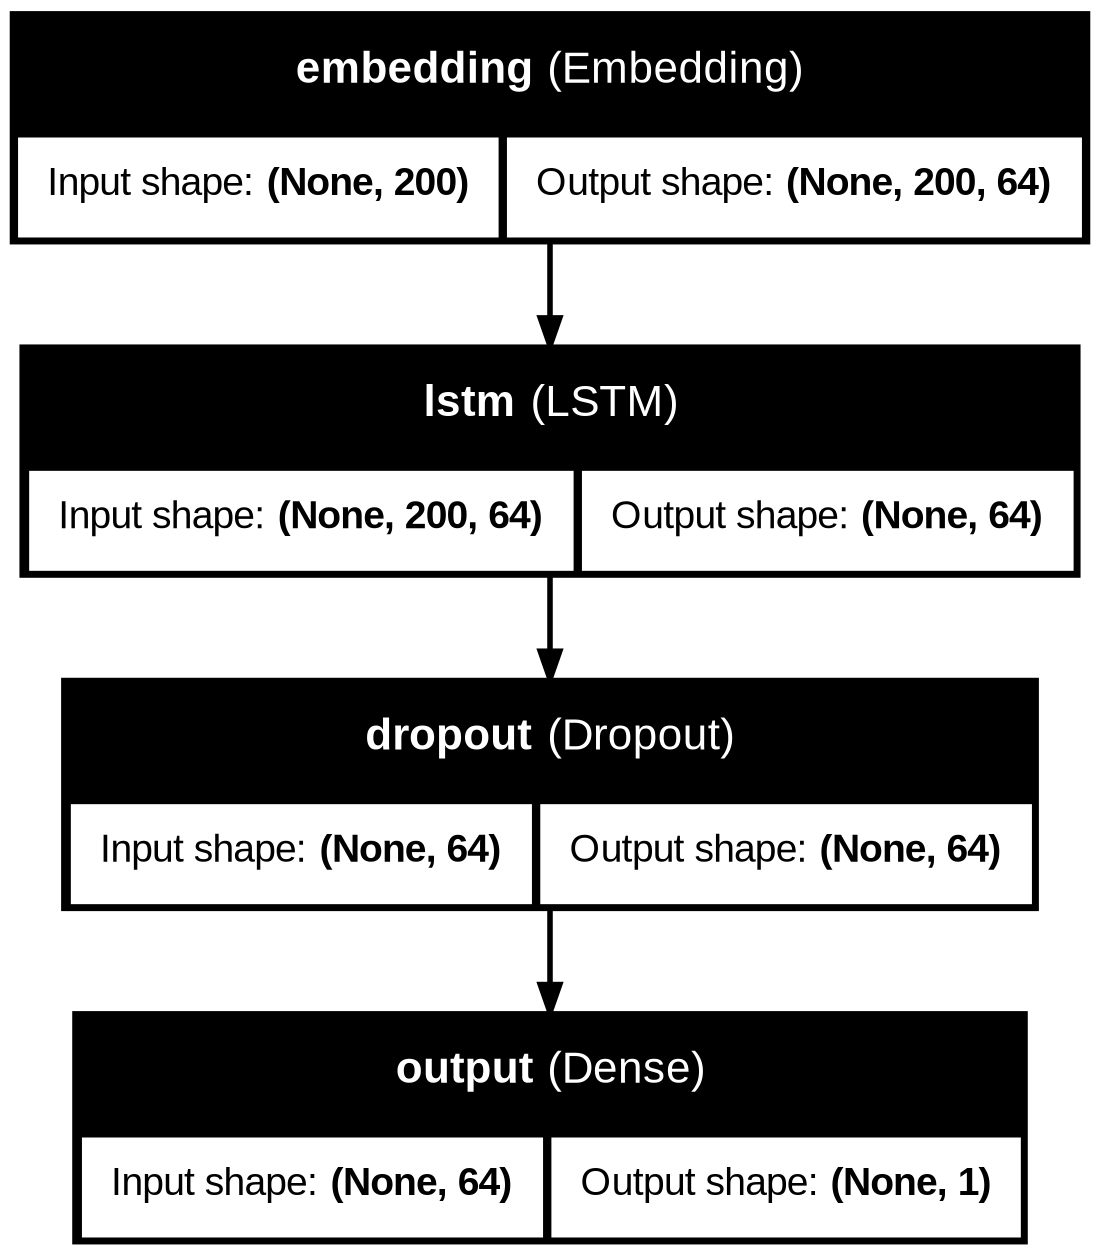

In [4]:
print(f"[{STUDENT_NAME} | {ROLL_NO}] PART B: Building the LSTM Model\n")

EMBED_DIM = 64

model = Sequential([
    Embedding(input_dim=VOCAB_SIZE, output_dim=EMBED_DIM, input_length=MAX_LEN, name="embedding"),
    LSTM(64, name="lstm"),
    Dropout(0.5, name="dropout"),
    Dense(1, activation="sigmoid", name="output")
], name=f"LSTM_Sentiment_{ROLL_NO}")

model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])

model.build(input_shape=(None, MAX_LEN))
model.summary()

try:
    tf.keras.utils.plot_model(model, to_file="lstm_model.png", show_shapes=True, show_layer_names=True)
    from IPython.display import Image, display
    display(Image("lstm_model.png"))
except Exception as e:
    print("Model diagram skipped (graphviz/pydot not available):", e)

## PART C: MODEL TRAINING AND PERFORMANCE EVALUATION

In [5]:
print(f"[{STUDENT_NAME} | {ROLL_NO}] PART C: Training the LSTM Model\n")

early_stop = EarlyStopping(monitor="val_loss", patience=2, restore_best_weights=True)

history = model.fit(
    x_train, y_train,
    epochs=8,
    batch_size=64,
    validation_data=(x_val, y_val),
    callbacks=[early_stop],
    verbose=1
)

# Record training / validation accuracy and loss
hist_df = pd.DataFrame({
    "Epoch": range(1, len(history.history["loss"]) + 1),
    "Train Accuracy": history.history["accuracy"],
    "Val Accuracy": history.history["val_accuracy"],
    "Train Loss": history.history["loss"],
    "Val Loss": history.history["val_loss"],
})
print("\nTraining history:")
display(hist_df.round(4))

[NIVASRI T | 24BAD081] PART C: Training the LSTM Model

Epoch 1/8
313/313 ━━━━━━━━━━━━━━━━━━━━ 10s 16ms/step - accuracy: 0.7531 - loss: 0.4973 - val_accuracy: 0.8150 - val_loss: 0.4143
Epoch 2/8
313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step - accuracy: 0.8823 - loss: 0.3023 - val_accuracy: 0.8456 - val_loss: 0.3940
Epoch 3/8
313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step - accuracy: 0.9153 - loss: 0.2363 - val_accuracy: 0.8114 - val_loss: 0.4544
Epoch 4/8
313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 14ms/step - accuracy: 0.9182 - loss: 0.2219 - val_accuracy: 0.8514 - val_loss: 0.4377

Training history:


,Epoch,Train Accuracy,Val Accuracy,Train Loss,Val Loss
0,1,0.7531,0.8150,0.4973,0.4143
1,2,0.8823,0.8456,0.3023,0.3940
2,3,0.9153,0.8114,0.2363,0.4544
3,4,0.9182,0.8514,0.2219,0.4377


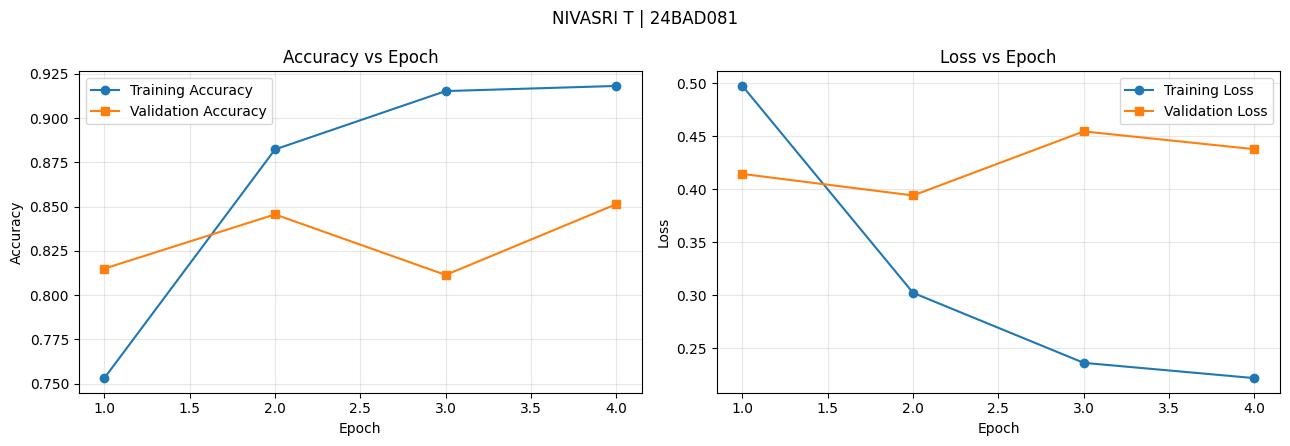

In [6]:
# Accuracy vs Epoch and Loss vs Epoch
epochs_range = hist_df["Epoch"]
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))

ax[0].plot(epochs_range, hist_df["Train Accuracy"], marker="o", label="Training Accuracy")
ax[0].plot(epochs_range, hist_df["Val Accuracy"], marker="s", label="Validation Accuracy")
ax[0].set_title("Accuracy vs Epoch"); ax[0].set_xlabel("Epoch"); ax[0].set_ylabel("Accuracy"); ax[0].legend(); ax[0].grid(alpha=.3)

ax[1].plot(epochs_range, hist_df["Train Loss"], marker="o", label="Training Loss")
ax[1].plot(epochs_range, hist_df["Val Loss"], marker="s", label="Validation Loss")
ax[1].set_title("Loss vs Epoch"); ax[1].set_xlabel("Epoch"); ax[1].set_ylabel("Loss"); ax[1].legend(); ax[1].grid(alpha=.3)

fig.suptitle(f"{STUDENT_NAME} | {ROLL_NO}")
plt.tight_layout(); plt.show()

[NIVASRI T | 24BAD081] Test Loss: 0.3929 | Test Accuracy: 0.8388



,Metric,Score
0,Accuracy,0.8388
1,Precision,0.8710
2,Recall,0.7954
3,F1-score,0.8315



Classification Report:

              precision    recall  f1-score   support

    Negative       0.81      0.88      0.85     12500
    Positive       0.87      0.80      0.83     12500

    accuracy                           0.84     25000
   macro avg       0.84      0.84      0.84     25000
weighted avg       0.84      0.84      0.84     25000



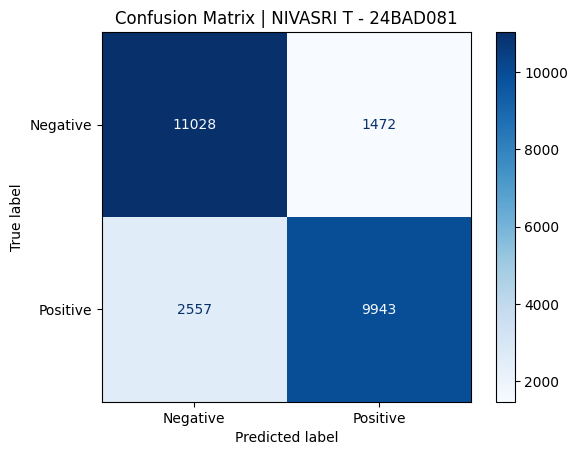

In [7]:
# Evaluate on the test dataset
test_loss, test_acc = model.evaluate(x_test, y_test, verbose=0)
print(f"[{STUDENT_NAME} | {ROLL_NO}] Test Loss: {test_loss:.4f} | Test Accuracy: {test_acc:.4f}\n")

y_prob = model.predict(x_test, verbose=0).ravel()
y_pred = (y_prob >= 0.5).astype(int)

acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
rec = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

metrics_df = pd.DataFrame({"Metric": ["Accuracy", "Precision", "Recall", "F1-score"],
                           "Score": [acc, prec, rec, f1]})
display(metrics_df.round(4))

print("\nClassification Report:\n")
print(classification_report(y_test, y_pred, target_names=["Negative", "Positive"]))

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Negative", "Positive"])
disp.plot(cmap="Blues", values_format="d")
plt.title(f"Confusion Matrix | {STUDENT_NAME} - {ROLL_NO}")
plt.show()

## PART D: SENTIMENT PREDICTION AND DEEP LEARNING EXPERIMENT MANAGEMENT

In [8]:
print(f"[{STUDENT_NAME} | {ROLL_NO}] PART D: Sentiment Prediction\n")

def predict_sentiment(text, threshold=0.5):
    seq = text_to_sequence(text)                                            # same vocabulary as training
    padded = pad_sequences([seq], maxlen=MAX_LEN, padding="pre", truncating="post")
    prob = float(model.predict(padded, verbose=0)[0][0])
    return ("Positive" if prob >= threshold else "Negative"), prob

test_reviews = [
    ("This movie was absolutely fantastic! The acting was brilliant and the story kept me engaged till the end.", "Positive"),
    ("A terrible film. The plot was boring, the dialogues were weak and I regret watching it.", "Negative"),
    ("I loved the cinematography and the soundtrack. A truly wonderful and moving experience.", "Positive"),
    ("Worst movie I have ever seen. Complete waste of time and money.", "Negative"),
    ("The film started slowly, but the performances were excellent and the ending was superb.", "Positive"),
    ("Not good at all. The characters were dull and the story made no sense.", "Negative"),
    ("An amazing masterpiece with great direction and a heartwarming story.", "Positive"),
    ("The movie was disappointing, poorly written and painfully long.", "Negative"),
]

rows = []
for text, expected in test_reviews:
    pred, prob = predict_sentiment(text)
    rows.append({"Review": text[:70] + "...", "Expected": expected, "Predicted": pred,
                 "Probability(Positive)": round(prob, 4),
                 "Match": "✔" if pred == expected else "✘"})

results_df = pd.DataFrame(rows)
display(results_df)
correct = (results_df["Match"] == "✔").sum()
print(f"\nCorrect predictions: {correct}/{len(results_df)}  ({correct/len(results_df):.0%})")

[NIVASRI T | 24BAD081] PART D: Sentiment Prediction



,Review,Expected,Predicted,Probability(Positive),Match
0,This movie was absolutely fantastic! The actin...,Positive,Positive,0.8437,✔
1,"A terrible film. The plot was boring, the dial...",Negative,Negative,0.0412,✔
2,I loved the cinematography and the soundtrack....,Positive,Positive,0.9841,✔
3,Worst movie I have ever seen. Complete waste o...,Negative,Negative,0.0196,✔
4,"The film started slowly, but the performances ...",Positive,Positive,0.9241,✔
5,Not good at all. The characters were dull and ...,Negative,Negative,0.1841,✔
6,An amazing masterpiece with great direction an...,Positive,Positive,0.9508,✔
7,"The movie was disappointing, poorly written an...",Negative,Negative,0.0666,✔



Correct predictions: 8/8  (100%)


In [9]:
# Try your own review
custom = input("Enter a movie review: ")
label, p = predict_sentiment(custom)
print(f"[{STUDENT_NAME} | {ROLL_NO}] Predicted: {label} (P(positive) = {p:.4f})")

Enter a movie review: This movie was absolutely worst!
[NIVASRI T | 24BAD081] Predicted: Negative (P(positive) = 0.0544)


### Observations
- The text was lowercased, cleaned and tokenized, converted to integer sequences with the IMDB vocabulary (top 10,000 words) and padded to 200 tokens.
- The Embedding → LSTM → Dense(sigmoid) model learned sequential and contextual patterns; training/validation curves and the confusion matrix show how well it generalises (see outputs above).
- Clearly positive/negative reviews are predicted with high confidence, whereas reviews with mixed or negated sentiment (e.g., *"started slowly, but ... excellent"*) get probabilities closer to 0.5 and are more likely to be misclassified.
- Limitations: limited vocabulary (OOV words ignored), review truncation to 200 tokens, and a small LSTM. Using bidirectional LSTM, pre-trained embeddings (GloVe) or a longer sequence length could improve results.

**Conclusion:** The LSTM-based model was successfully implemented for sentiment analysis of IMDB movie reviews and classified new review sentences as Positive or Negative.